# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook is a **starter notebook** for the three parts of the lab:

1. NLP  
2. Time Series  
3. Neural Networks  

Use the comments and TODO prompts to guide your work. The notebook is intentionally incomplete so you can implement the analysis yourself.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


**Load data (Google Colab):** upload `amazon_reviews_lab.csv` here first. All three parts read the file from the Colab session.

In [1]:
# Load the data in Google Colab: run this cell and choose amazon_reviews_lab.csv when asked to upload
# (the file is saved in the Colab session, so the pd.read_csv calls below can find it)
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Not running in Colab, using the local amazon_reviews_lab.csv file")

Not running in Colab, using the local amazon_reviews_lab.csv file


In [1]:
# Part 1: NLP
import os, warnings
warnings.filterwarnings('ignore')
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag
from nltk.util import ngrams

# Download the NLTK resources
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4',
            'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(pkg, quiet=True)

np.random.seed(42)

# Load the dataset
df = pd.read_csv('amazon_reviews_lab.csv')
df.head()

,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


Shape: (997, 9)

Missing values: 0

Rating counts:
rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64

Review length (words):
count     997.000000
mean      146.374122
std       216.126770
min         5.000000
25%        32.000000
50%        67.000000
75%       165.000000
max      2079.000000
Name: word_count, dtype: float64


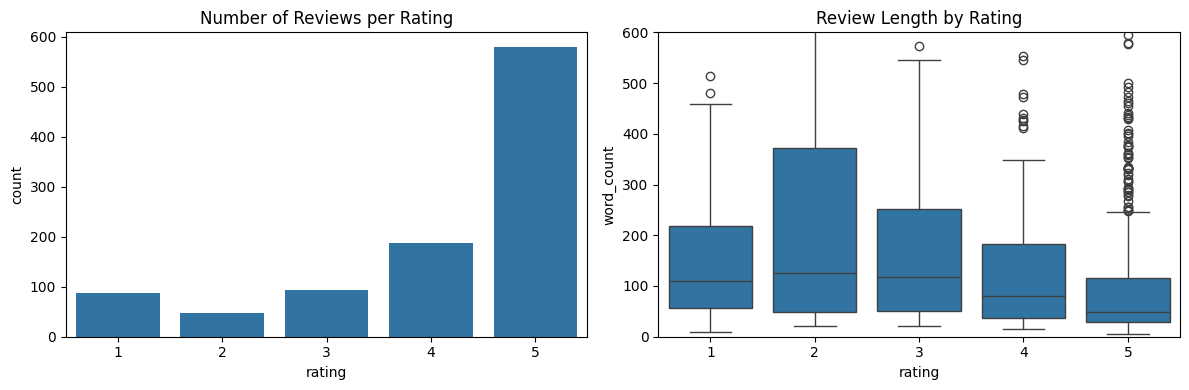

In [2]:
# Explore the dataset
print("Shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
print("\nRating counts:")
print(df['rating'].value_counts().sort_index())

# Review length in words
df['word_count'] = df['review_text'].apply(lambda x: len(x.split()))
print("\nReview length (words):")
print(df['word_count'].describe())

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.countplot(x='rating', data=df)
plt.title('Number of Reviews per Rating')
plt.subplot(1, 2, 2)
sns.boxplot(x='rating', y='word_count', data=df)
plt.ylim(0, 600)
plt.title('Review Length by Rating')
plt.tight_layout()
plt.show()

In [3]:
# Preprocessing tools
# Keep "no", "not" and "nor" because they change the meaning of a review
stop_words = set(stopwords.words('english')) - {'no', 'not', 'nor'}
lemmatizer = WordNetLemmatizer()

# Convert POS tags to WordNet POS tags
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

def preprocess_text(text):
    # 1. lowercase
    text = text.lower()
    # 2. remove HTML tags and URLs
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    # handle contractions (can't -> can not, isn't -> is not)
    text = text.replace("can't", "can not").replace("won't", "will not").replace("n't", " not")
    # 3. remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)
    # 4. tokenize
    tokens = word_tokenize(text)
    # 5. keep alphabetic tokens longer than one letter
    tokens = [t for t in tokens if t.isalpha() and len(t) > 1]
    # 6. remove stopwords
    tokens = [t for t in tokens if t not in stop_words]
    # 7. lemmatize with POS tags
    tagged = pos_tag(tokens)
    tokens = [lemmatizer.lemmatize(word, get_wordnet_pos(tag)) for word, tag in tagged]
    # 8. return the cleaned tokens
    return tokens

# Apply to all reviews
df['processed_tokens'] = df['review_text'].apply(preprocess_text)

# Check the quality of the preprocessing
for i in [0, 5]:
    print("Original: ", df['review_text'][i][:200])
    print("Processed:", df['processed_tokens'][i][:25])
    print()
print("Edge cases:", preprocess_text("It isn't good!! Visit http://example.com <br> 100% waste."))

raw_tokens = [t for text in df['review_text'] for t in text.lower().split()]
all_tokens = [t for tokens in df['processed_tokens'] for t in tokens]
print(f"Total tokens: {len(raw_tokens)} -> {len(all_tokens)}")
print(f"Unique tokens: {len(set(raw_tokens))} -> {len(set(all_tokens))}")
print(f"Empty reviews after cleaning: {(df['processed_tokens'].apply(len) == 0).sum()}")

Original:  This film is definitely not for anyone who is especially fond of the independent, delightfully manipulative and clever boy who was the brain child of Samuel Clemens's classic.As one example, the book 
Processed: ['film', 'definitely', 'not', 'anyone', 'especially', 'fond', 'independent', 'delightfully', 'manipulative', 'clever', 'boy', 'brain', 'child', 'samuel', 'clemens', 'classic', 'one', 'example', 'book', 'great', 'fun', 'scene', 'involve', 'aunt', 'polly']

Original:  For the money you can't go wrong. Yes, it has a litlle play in the mechanism but, you can adjust your mounting to accomodate that. It works great and frees up counter space. I would do it all again. W
Processed: ['money', 'not', 'go', 'wrong', 'yes', 'litlle', 'play', 'mechanism', 'adjust', 'mount', 'accomodate', 'work', 'great', 'free', 'counter', 'space', 'would', 'spend', 'time']

Edge cases: ['not', 'good', 'visit', 'waste']
Total tokens: 145935 -> 74050
Unique tokens: 15524 -> 6005
Empty reviews afte

[('not', 2005), ('nook', 1564), ('book', 986), ('use', 821), ('read', 685), ('get', 649), ('work', 615), ('one', 596), ('kindle', 593), ('buy', 548), ('screen', 537), ('like', 501), ('well', 449), ('great', 446), ('tablet', 440), ('tv', 420), ('good', 416), ('no', 408), ('would', 408), ('mount', 405)]
[(('barnes', 'noble'), 166), (('nook', 'color'), 135), (('touch', 'screen'), 100), (('battery', 'life'), 98), (('sd', 'card'), 90), (('work', 'great'), 86), (('nook', 'hd'), 80), (('work', 'well'), 75), (('read', 'book'), 75), (('could', 'not'), 64), (('nook', 'tablet'), 64), (('page', 'turn'), 61), (('kindle', 'fire'), 61), (('wall', 'mount'), 57), (('not', 'work'), 56), (('would', 'not'), 55), (('not', 'use'), 54), (('no', 'problem'), 53), (('work', 'fine'), 52), (('buy', 'nook'), 50)]


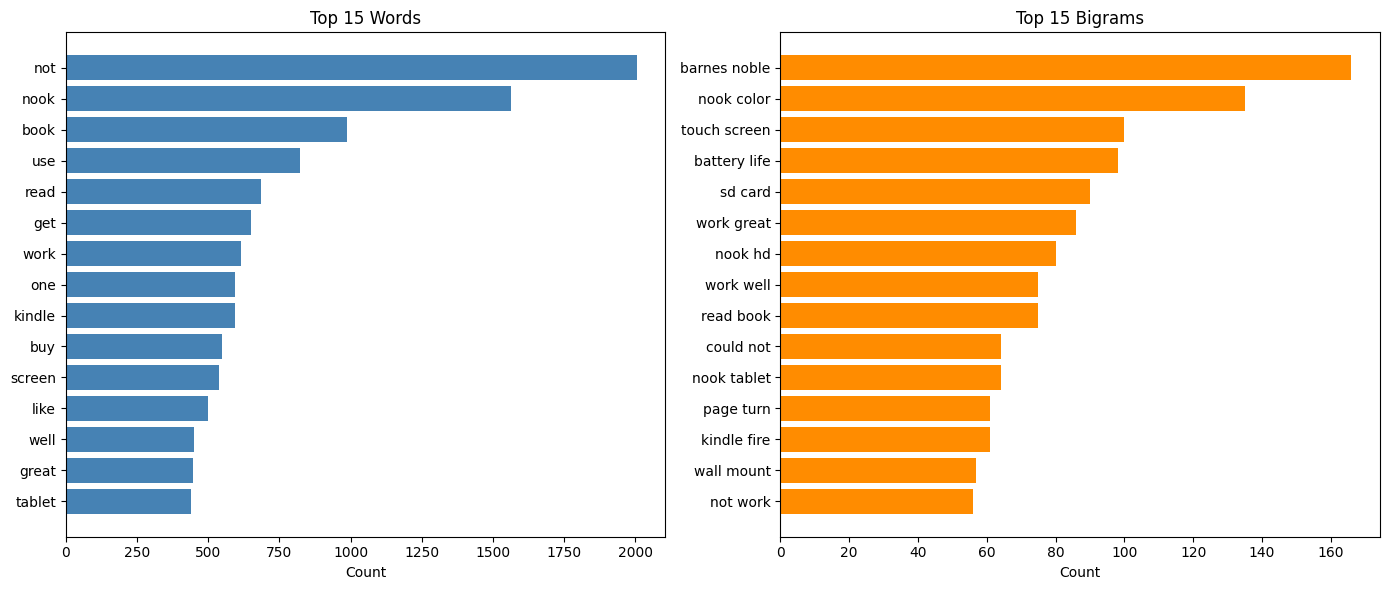

In [4]:
# Most common words
word_counts = Counter(all_tokens)
print(word_counts.most_common(20))

# Most common bigrams (built inside each review, so words from different reviews are not joined)
bigram_counts = Counter(b for tokens in df['processed_tokens'] for b in ngrams(tokens, 2))
print(bigram_counts.most_common(20))

# Plot the top words and bigrams
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
words, counts = zip(*word_counts.most_common(15))
plt.barh(words[::-1], counts[::-1], color='steelblue')
plt.title('Top 15 Words')
plt.xlabel('Count')
plt.subplot(1, 2, 2)
bigrams, counts = zip(*bigram_counts.most_common(15))
plt.barh([' '.join(b) for b in bigrams][::-1], counts[::-1], color='darkorange')
plt.title('Top 15 Bigrams')
plt.xlabel('Count')
plt.tight_layout()
plt.show()

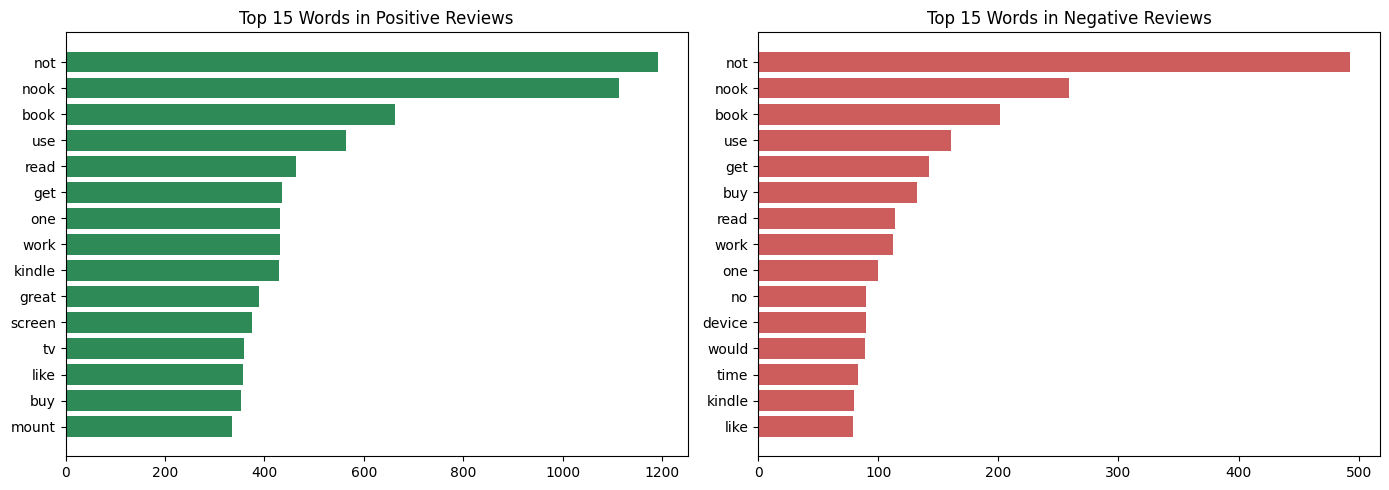

Words most linked to negative reviews: ['not', 'return', 'try', 'even', 'customer', 'buy', 'service', 'update', 'charge', 'could', 'credit', 'time']
Words most linked to positive reviews: ['great', 'tv', 'nook', 'mount', 'easy', 'price', 'kindle', 'love', 'color', 'screen', 'need', 'good']
Top negative bigrams: [('barnes noble', 39), ('customer service', 26), ('not work', 25), ('credit card', 21), ('would not', 20), ('could not', 19), ('read book', 18), ('battery life', 15), ('not use', 15), ('buy nook', 15)]


In [5]:
# Compare words in positive and negative reviews
pos_tokens = [t for tokens in df[df['sentiment_label'] == 'positive']['processed_tokens'] for t in tokens]
neg_tokens = [t for tokens in df[df['sentiment_label'] == 'negative']['processed_tokens'] for t in tokens]
pos_counts = Counter(pos_tokens)
neg_counts = Counter(neg_tokens)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
words, counts = zip(*pos_counts.most_common(15))
plt.barh(words[::-1], counts[::-1], color='seagreen')
plt.title('Top 15 Words in Positive Reviews')
plt.subplot(1, 2, 2)
words, counts = zip(*neg_counts.most_common(15))
plt.barh(words[::-1], counts[::-1], color='indianred')
plt.title('Top 15 Words in Negative Reviews')
plt.tight_layout()
plt.show()

# Words that are much more common in one group (share of all words in the group)
diff = {w: pos_counts[w] / len(pos_tokens) - neg_counts[w] / len(neg_tokens)
        for w in set(pos_tokens) | set(neg_tokens)}
ranked = sorted(diff.items(), key=lambda x: x[1])
print("Words most linked to negative reviews:", [w for w, _ in ranked[:12]])
print("Words most linked to positive reviews:", [w for w, _ in ranked[::-1][:12]])

# Top bigrams in negative reviews
neg_bigrams = Counter(b for tokens in df[df['sentiment_label'] == 'negative']['processed_tokens'] for b in ngrams(tokens, 2))
print("Top negative bigrams:", [(' '.join(b), c) for b, c in neg_bigrams.most_common(10)])

**Part 1 notes:**
- Loaded the reviews and checked shape, ratings and review length
- Built `preprocess_text`: lowercase, removed HTML tags and URLs, handled contractions, removed punctuation and numbers, tokenized, removed stopwords (kept "no", "not", "nor") and lemmatized with POS tags
- Checked the cleaning with before/after examples, edge cases and token counts (145,935 to 74,050 tokens; 15,524 to 6,005 unique tokens)
- Counted top words and bigrams, and compared positive and negative reviews with bar charts

**Reflection:** The most common words are "nook", "kindle", "book", "screen" and "tablet", so most reviews are about e-readers and tablets. Positive reviews use words like "great", "easy", "love" and "price". Negative reviews use "return", "customer service", "credit card", "not work" and "battery life". This suggests customers are happy with ease of use and price, and unhappy with service, billing and things that stop working. Keeping "not" mattered, because it is the most common word and changes the meaning of the words next to it.

## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


Earliest: 2000-05-12 00:00:00
Latest:   2014-07-17 00:00:00

Reviews per year:
timestamp
2000      1
2002      1
2005      2
2007      1
2008      3
2009      9
2010    131
2011    164
2012    200
2013    325
2014    160
Name: count, dtype: int64


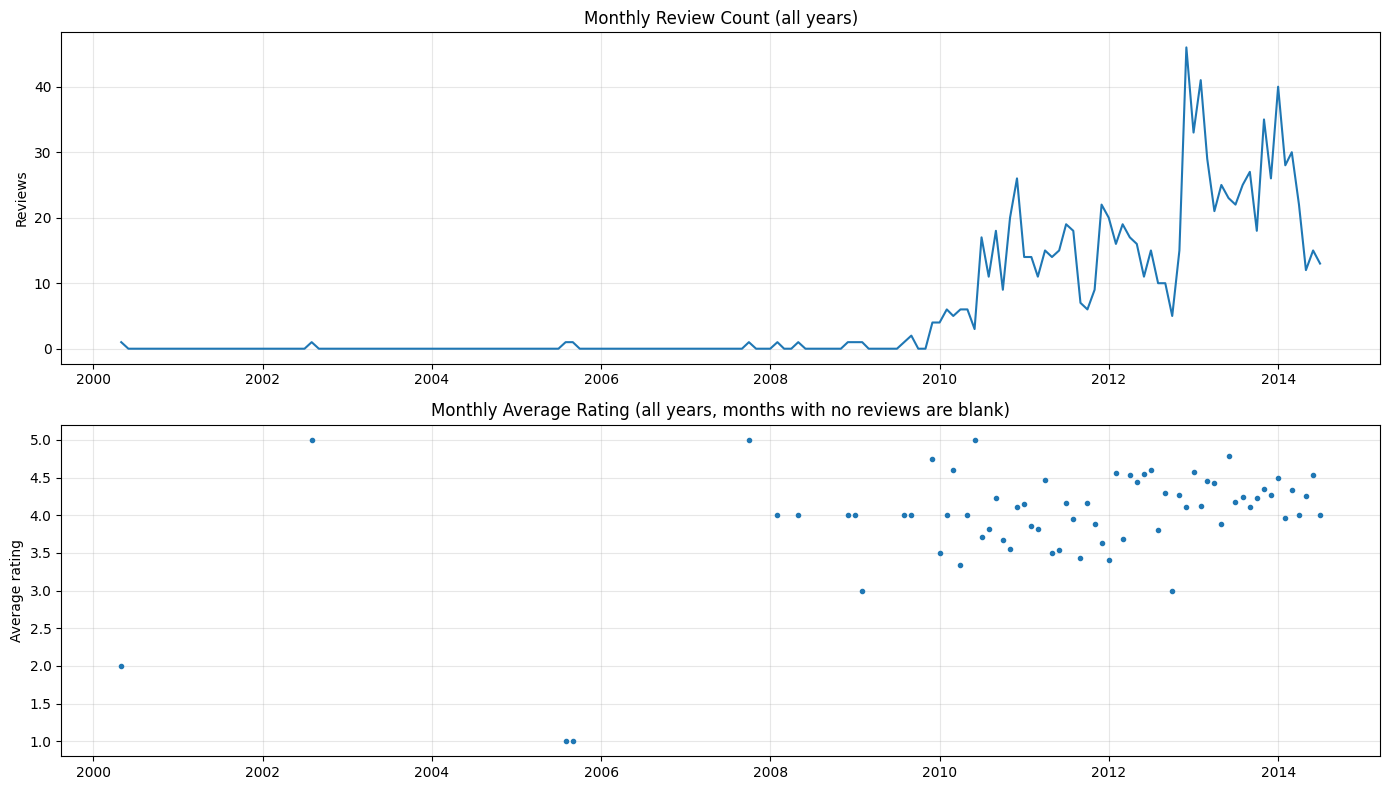

In [6]:
# Part 2: Time Series
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load the dataset and convert the timestamp column
df_ts = pd.read_csv('amazon_reviews_lab.csv')
df_ts['timestamp'] = pd.to_datetime(df_ts['timestamp'])

# Date range
print("Earliest:", df_ts['timestamp'].min())
print("Latest:  ", df_ts['timestamp'].max())
print("\nReviews per year:")
print(df_ts['timestamp'].dt.year.value_counts().sort_index())

# Monthly review count and average rating
df_ts = df_ts.set_index('timestamp')
monthly_review_count = df_ts['rating'].resample('MS').count()
monthly_avg_rating = df_ts['rating'].resample('MS').mean()

# Plot monthly review volume and average rating
plt.figure(figsize=(14, 8))
plt.subplot(2, 1, 1)
plt.plot(monthly_review_count)
plt.title('Monthly Review Count (all years)')
plt.ylabel('Reviews')
plt.grid(True, alpha=0.3)
plt.subplot(2, 1, 2)
plt.plot(monthly_avg_rating, marker='o', markersize=3, linestyle='')
plt.title('Monthly Average Rating (all years, months with no reviews are blank)')
plt.ylabel('Average rating')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Months used: 54 | months with no reviews: 0


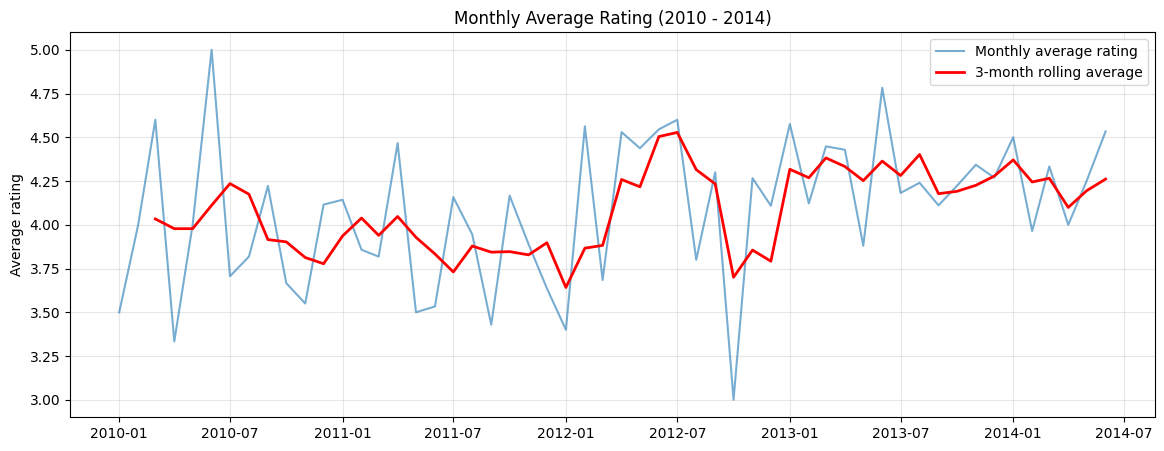

Average rating by year:
timestamp
2010    3.91
2011    3.88
2012    4.14
2013    4.30
2014    4.25
Name: rating, dtype: float64


In [7]:
# Before 2010 there are almost no reviews, so use January 2010 to June 2014
# (July 2014 is left out because the data stops in the middle of the month)
count_ts = monthly_review_count['2010-01-01':'2014-06-01']
rating_ts = monthly_avg_rating['2010-01-01':'2014-06-01']
print("Months used:", len(count_ts), "| months with no reviews:", (count_ts == 0).sum())

# 3-month rolling average of the monthly average rating
rolling_avg_rating = rating_ts.rolling(window=3).mean()

plt.figure(figsize=(14, 5))
plt.plot(rating_ts, label='Monthly average rating', alpha=0.6)
plt.plot(rolling_avg_rating, label='3-month rolling average', color='red', linewidth=2)
plt.title('Monthly Average Rating (2010 - 2014)')
plt.ylabel('Average rating')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Average rating by year:")
print(df_ts['rating'].groupby(df_ts.index.year).mean().loc[2010:2014].round(2))

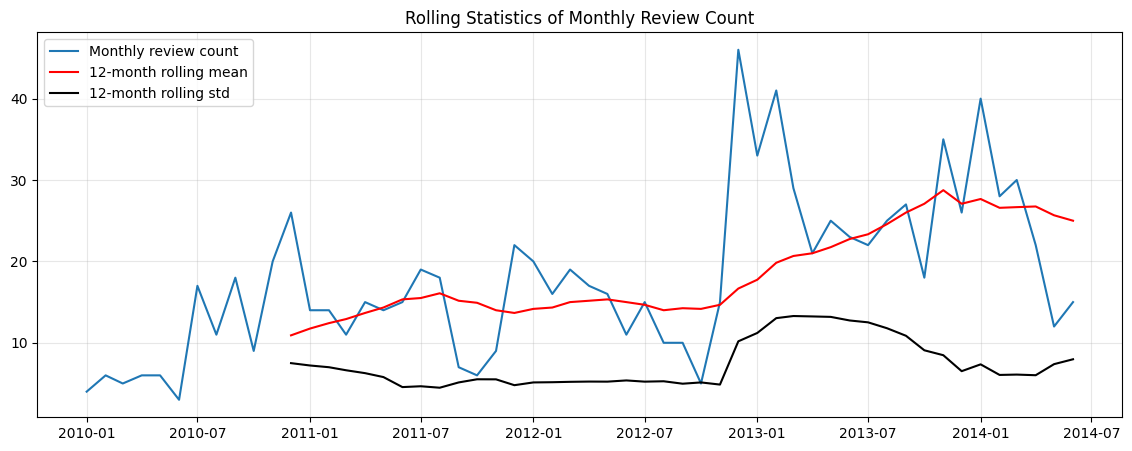

Original count: ADF statistic = -3.5472, p-value = 0.0069
   critical values: {'1%': np.float64(-3.5602), '5%': np.float64(-2.9179), '10%': np.float64(-2.5968)}
Log count: ADF statistic = -3.6192, p-value = 0.0054
   critical values: {'1%': np.float64(-3.5602), '5%': np.float64(-2.9179), '10%': np.float64(-2.5968)}
Differenced count: ADF statistic = -4.6484, p-value = 0.0001
   critical values: {'1%': np.float64(-3.5925), '5%': np.float64(-2.9315), '10%': np.float64(-2.6041)}
Log and differenced count: ADF statistic = -4.4383, p-value = 0.0003
   critical values: {'1%': np.float64(-3.5925), '5%': np.float64(-2.9315), '10%': np.float64(-2.6041)}


In [8]:
# Stationarity: rolling statistics and ADF test on the monthly review count
roll_mean = count_ts.rolling(window=12).mean()
roll_std = count_ts.rolling(window=12).std()

plt.figure(figsize=(14, 5))
plt.plot(count_ts, label='Monthly review count')
plt.plot(roll_mean, label='12-month rolling mean', color='red')
plt.plot(roll_std, label='12-month rolling std', color='black')
plt.title('Rolling Statistics of Monthly Review Count')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

def adf_report(series, name):
    result = adfuller(series.dropna())
    print(f"{name}: ADF statistic = {result[0]:.4f}, p-value = {result[1]:.4f}")
    print("   critical values:", {k: round(v, 4) for k, v in result[4].items()})

adf_report(count_ts, "Original count")

# Transformations: log and first-order differencing
count_log = np.log1p(count_ts)
count_diff = count_ts.diff().dropna()
count_log_diff = count_log.diff().dropna()
adf_report(count_log, "Log count")
adf_report(count_diff, "Differenced count")
adf_report(count_log_diff, "Log and differenced count")

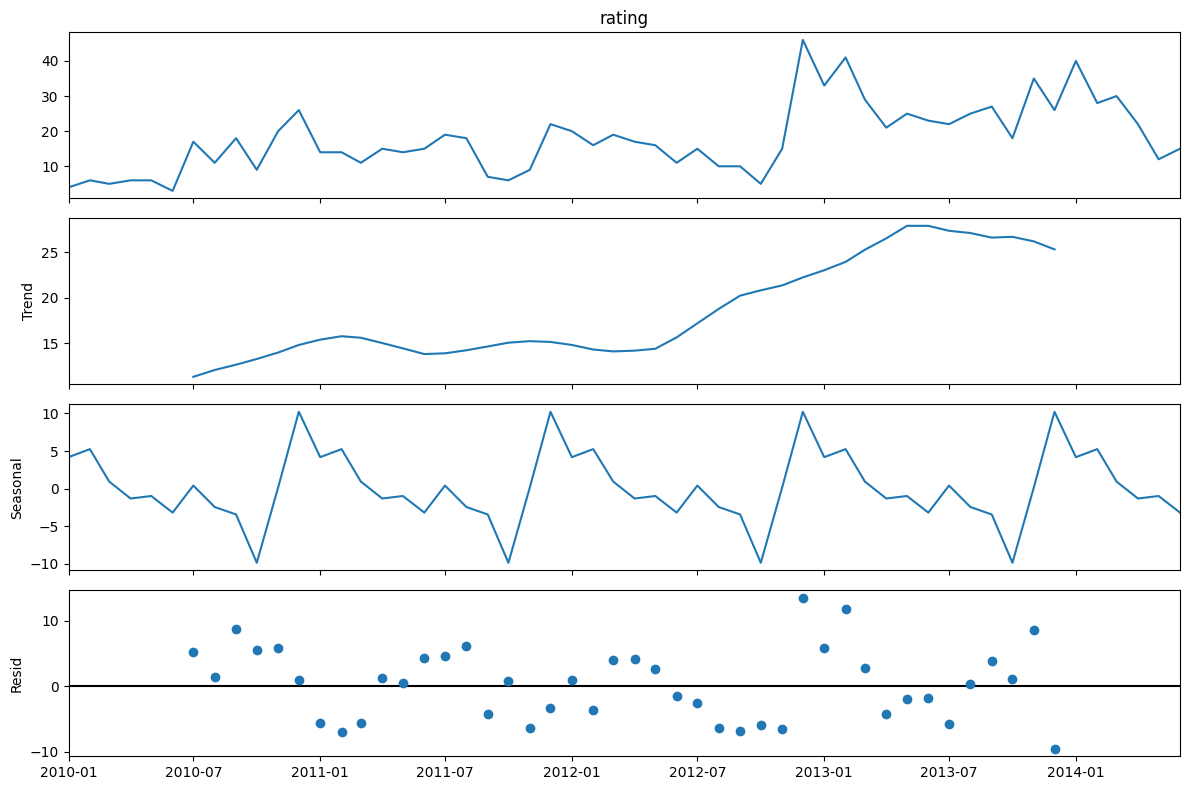

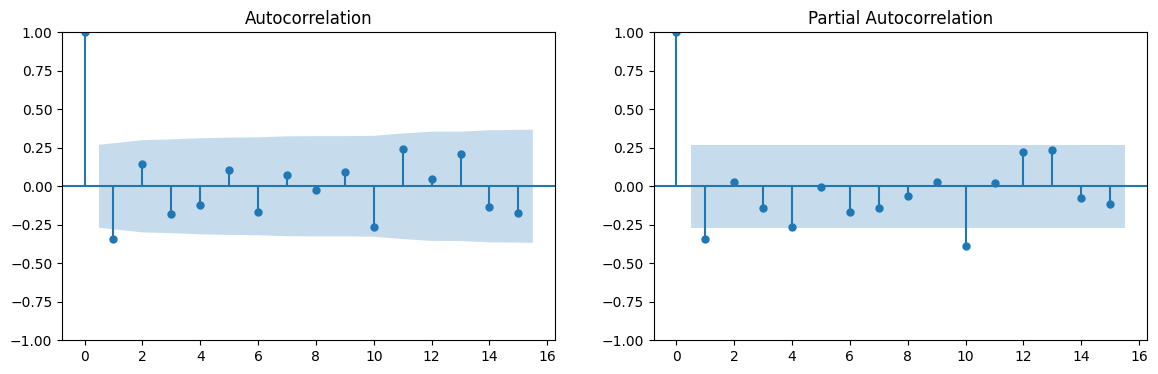

In [9]:
# Decomposition into trend, seasonal and residual parts
decomp = seasonal_decompose(count_ts, model='additive', period=12)
decomp.plot()
plt.gcf().set_size_inches(12, 8)
plt.tight_layout()
plt.show()

# ACF and PACF of the differenced series
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(count_diff, lags=15, ax=axes[0])
plot_pacf(count_diff, lags=15, ax=axes[1])
plt.show()

In [10]:
# Split: train on all months except the last 12, test on the last 12
train = count_ts.iloc[:-12]
test = count_ts.iloc[-12:]

# Compare ARIMA models using AIC / BIC (training data) and error on the test data
orders = [(1, 0, 0), (2, 0, 0), (1, 1, 0), (0, 1, 1), (1, 1, 1), (2, 1, 2)]
results = []
fits = {}
for order in orders:
    fit = ARIMA(train, order=order).fit()
    fc = fit.forecast(steps=12)
    fits[order] = fc
    results.append({'order': order, 'AIC': round(fit.aic, 1), 'BIC': round(fit.bic, 1),
                    'MAE': round(mean_absolute_error(test, fc), 2),
                    'RMSE': round(np.sqrt(mean_squared_error(test, fc)), 2)})

# Simple baseline: always predict the training average of the last 12 months
naive = pd.Series(train.iloc[-12:].mean(), index=test.index)
results.append({'order': 'baseline (last 12-month mean)', 'AIC': None, 'BIC': None,
                'MAE': round(mean_absolute_error(test, naive), 2),
                'RMSE': round(np.sqrt(mean_squared_error(test, naive)), 2)})
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

                        order   AIC   BIC  MAE  RMSE
                    (1, 0, 0) 292.4 297.6 9.03 11.40
                    (2, 0, 0) 294.2 301.2 8.81 11.22
                    (1, 1, 0) 289.1 292.5 6.28  7.81
                    (0, 1, 1) 288.6 292.0 6.24  7.77
                    (1, 1, 1) 287.2 292.4 6.43  8.04
                    (2, 1, 2) 290.0 298.6 6.30  7.72
baseline (last 12-month mean)   NaN   NaN 6.38  7.96


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Best order by AIC: (1, 1, 1)


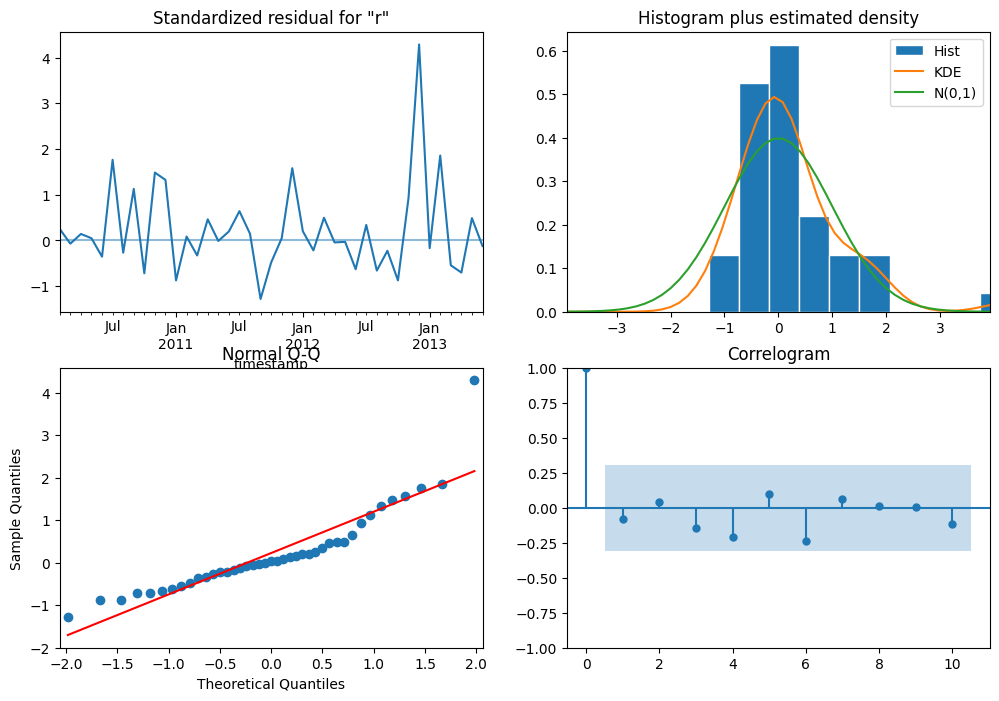

MAE: 6.43 | RMSE: 8.04 | MAPE: 27.6%


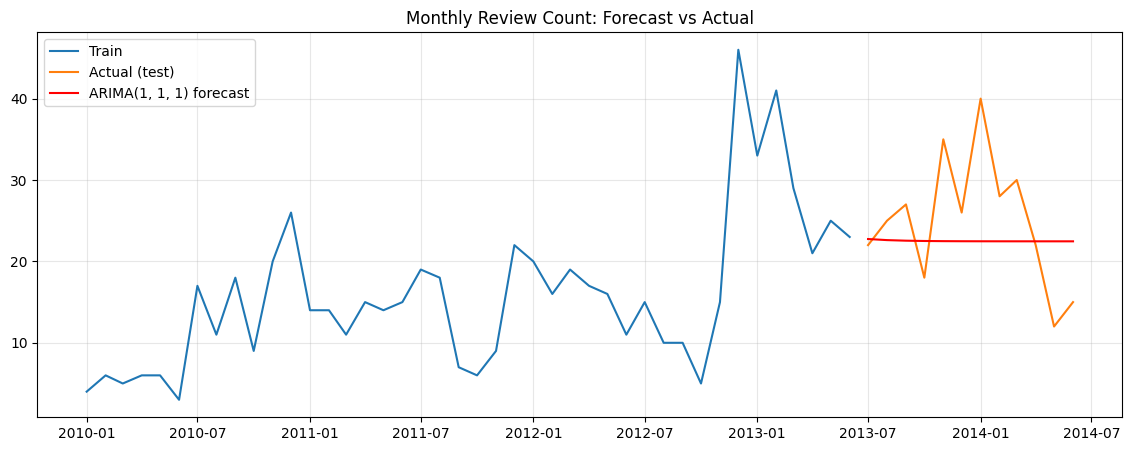

In [11]:
# Pick the model with the lowest AIC and check it
best_order = min(orders, key=lambda o: results_df.loc[results_df['order'] == o, 'AIC'].iloc[0])
print("Best order by AIC:", best_order)
best_fit = ARIMA(train, order=best_order).fit()
best_fit.plot_diagnostics(figsize=(12, 8))
plt.show()

# Forecast vs actual
forecast = best_fit.forecast(steps=12)
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))
mape = np.mean(np.abs((test - forecast) / test)) * 100
print(f"MAE: {mae:.2f} | RMSE: {rmse:.2f} | MAPE: {mape:.1f}%")

plt.figure(figsize=(14, 5))
plt.plot(train, label='Train')
plt.plot(test, label='Actual (test)')
plt.plot(forecast, label=f'ARIMA{best_order} forecast', color='red')
plt.title('Monthly Review Count: Forecast vs Actual')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Part 2 notes:**
- Converted timestamps, checked the date range and resampled to monthly review count and average rating
- Used January 2010 to June 2014 for modeling, because there are almost no reviews before 2010 and July 2014 is a partial month
- Plotted monthly volume, average rating and a 3-month rolling average
- Tested stationarity with rolling statistics and the ADF test (original, log, differenced, log and differenced)
- Decomposed the series and plotted ACF and PACF
- Compared six ARIMA models by AIC, BIC, MAE and RMSE, plus a simple baseline, then checked diagnostics and forecasted the last 12 months

**Reflection:** Review volume grew from 131 reviews in 2010 to 325 in 2013, and the average rating rose from 3.91 to 4.30. The monthly count is already stationary at the 5% level (ADF p-value 0.0069), and differencing made it even more stationary (p-value 0.0001). ARIMA(1,1,1) had the lowest AIC (287.2). Its test errors were MAE 6.43, RMSE 8.04 and MAPE 27.6%. This is about the same as the simple baseline (MAE 6.38), so the forecast is not much better than predicting the recent average. There are only 54 months of data, so the forecasts are rough and should be used for planning only.

## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


In [12]:
# Part 3: Neural Networks
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

np.random.seed(42)
tf.random.set_seed(42)

# X = review text, y = rating (shifted to 0-4 for the model)
df_nn = pd.read_csv('amazon_reviews_lab.csv')
X = df_nn['review_text']
y = df_nn['rating'] - 1

# Split first (stratified), then fit TF-IDF on the training text only
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

vectorizer = TfidfVectorizer(max_features=2000, stop_words='english')
X_train = vectorizer.fit_transform(X_train_text).toarray()
X_test = vectorizer.transform(X_test_text).toarray()
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

# One-hot encode the target
y_train_cat = to_categorical(y_train, num_classes=5)
y_test_cat = to_categorical(y_test, num_classes=5)

# Baseline: always predict the most common rating (5 stars)
print(f"Majority-class baseline accuracy: {(y_test == 4).mean():.4f}")

I0000 00:00:1791877760.108525      94 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791877773.397636      94 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791877780.619701      94 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Train shape: (797, 2000) | Test shape: (200, 2000)
Majority-class baseline accuracy: 0.5800


In [13]:
# Function to build a model so we can try different settings
def build_model(dropout=0.3, optimizer='adam'):
    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(128, activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(64, activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(5, activation='softmax')
    ])
    model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
    return model

build_model().summary()

# Try three settings and compare
configs = {
    'Adam + dropout 0.3': dict(dropout=0.3, optimizer='adam'),
    'Adam + no dropout': dict(dropout=0.0, optimizer='adam'),
    'RMSprop + dropout 0.3': dict(dropout=0.3, optimizer='rmsprop'),
}
histories = {}
models = {}
rows = []
for name, cfg in configs.items():
    tf.random.set_seed(42)
    model = build_model(**cfg)
    es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    history = model.fit(X_train, y_train_cat, validation_split=0.2, epochs=40,
                        batch_size=32, callbacks=[es], verbose=0)
    histories[name] = history
    models[name] = model
    test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
    pred = model.predict(X_test, verbose=0).argmax(axis=1)
    rows.append({'model': name, 'epochs': len(history.history['loss']),
                 'best val_accuracy': round(max(history.history['val_accuracy']), 4),
                 'test accuracy': round(test_acc, 4),
                 'test macro F1': round(f1_score(y_test, pred, average='macro'), 4)})
comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       256,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 264,709 (1.01 MB)

 Trainable params: 264,709 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

                model  epochs  best val_accuracy  test accuracy  test macro F1
   Adam + dropout 0.3      11             0.5875          0.585         0.1862
    Adam + no dropout      10             0.6062          0.590         0.1831
RMSprop + dropout 0.3      11             0.6000          0.585         0.1595


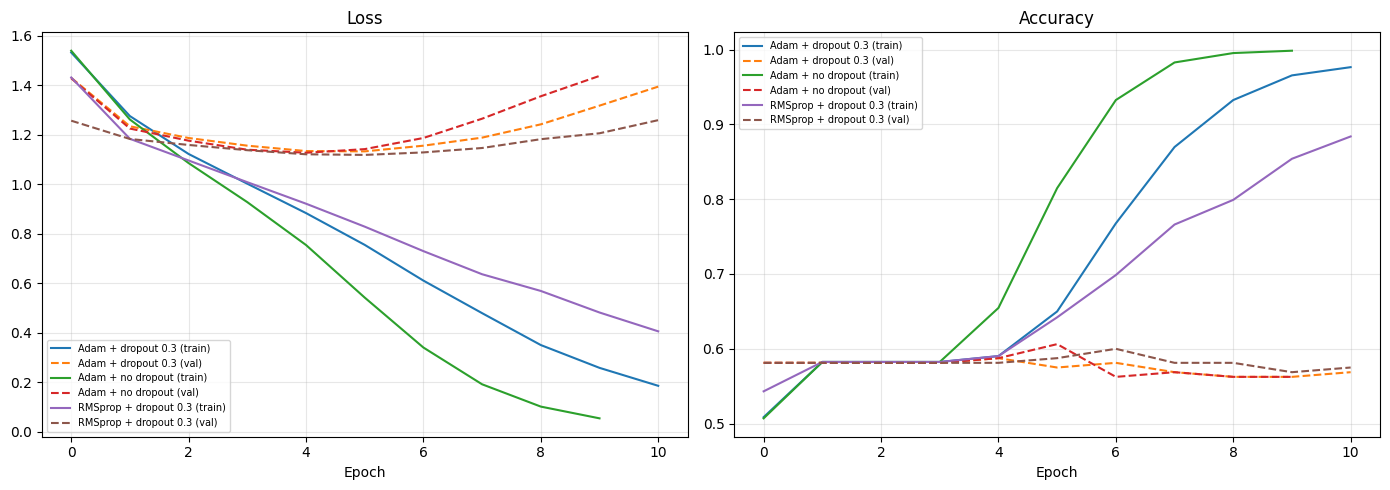

In [14]:
# Training curves for all three models
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
for name, h in histories.items():
    plt.plot(h.history['loss'], label=f'{name} (train)')
    plt.plot(h.history['val_loss'], linestyle='--', label=f'{name} (val)')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend(fontsize=7)
plt.grid(True, alpha=0.3)
plt.subplot(1, 2, 2)
for name, h in histories.items():
    plt.plot(h.history['accuracy'], label=f'{name} (train)')
    plt.plot(h.history['val_accuracy'], linestyle='--', label=f'{name} (val)')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend(fontsize=7)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Best model: Adam + no dropout
Test accuracy: 0.59

              precision    recall  f1-score   support

      1 star       0.00      0.00      0.00        17
     2 stars       0.00      0.00      0.00        10
     3 stars       0.00      0.00      0.00        19
     4 stars       0.36      0.11      0.16        38
     5 stars       0.61      0.98      0.75       116

    accuracy                           0.59       200
   macro avg       0.19      0.22      0.18       200
weighted avg       0.42      0.59      0.47       200



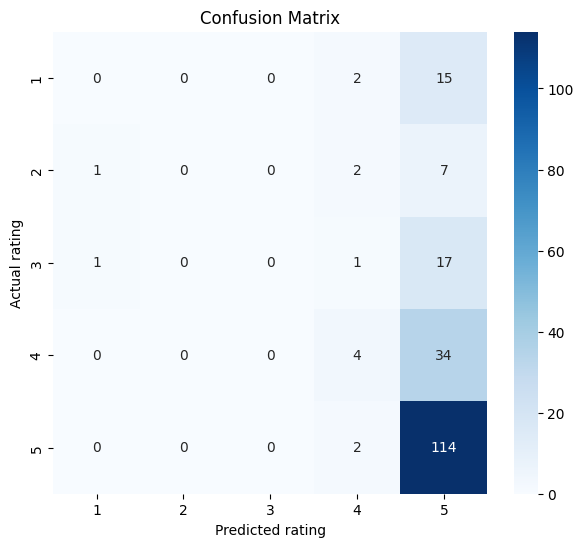

In [15]:
# Use the best model by validation accuracy and evaluate it on the test set
best_name = comparison.sort_values('best val_accuracy', ascending=False).iloc[0]['model']
best_model = models[best_name]
print("Best model:", best_name)

predictions = best_model.predict(X_test, verbose=0).argmax(axis=1)
print("Test accuracy:", round(accuracy_score(y_test, predictions), 4))
print()
print(classification_report(y_test, predictions, target_names=['1 star', '2 stars', '3 stars', '4 stars', '5 stars'], zero_division=0))

cm = confusion_matrix(y_test, predictions)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5])
plt.xlabel('Predicted rating')
plt.ylabel('Actual rating')
plt.title('Confusion Matrix')
plt.show()

In [16]:
# Improvement: class weights, so the rare ratings count more during training
weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(weights))
print("Class weights:", {k: round(v, 2) for k, v in class_weights.items()})

tf.random.set_seed(42)
weighted_model = build_model(**configs[best_name])
es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
weighted_history = weighted_model.fit(X_train, y_train_cat, validation_split=0.2, epochs=40,
                                      batch_size=32, callbacks=[es], class_weight=class_weights, verbose=0)
weighted_pred = weighted_model.predict(X_test, verbose=0).argmax(axis=1)

print(f"Without class weights: accuracy {accuracy_score(y_test, predictions):.4f}, macro F1 {f1_score(y_test, predictions, average='macro'):.4f}")
print(f"With class weights:    accuracy {accuracy_score(y_test, weighted_pred):.4f}, macro F1 {f1_score(y_test, weighted_pred, average='macro'):.4f}")
print()
print(classification_report(y_test, weighted_pred, target_names=['1 star', '2 stars', '3 stars', '4 stars', '5 stars'], zero_division=0))

Class weights: {0: np.float64(2.28), 1: np.float64(4.19), 2: np.float64(2.13), 3: np.float64(1.06), 4: np.float64(0.34)}


Without class weights: accuracy 0.5900, macro F1 0.1831
With class weights:    accuracy 0.4800, macro F1 0.2513

              precision    recall  f1-score   support

      1 star       0.18      0.12      0.14        17
     2 stars       0.20      0.10      0.13        10
     3 stars       0.09      0.05      0.07        19
     4 stars       0.23      0.26      0.25        38
     5 stars       0.63      0.71      0.67       116

    accuracy                           0.48       200
   macro avg       0.27      0.25      0.25       200
weighted avg       0.44      0.48      0.46       200



**Part 3 notes:**
- Split the data 80/20 (stratified), fitted TF-IDF (2,000 features) on the training text only and one-hot encoded the ratings
- Built a network with two hidden layers (128 and 64 neurons, ReLU), dropout and a softmax output
- Compared three settings (Adam with dropout, Adam without dropout, RMSprop with dropout) using early stopping, and plotted the training curves
- Evaluated the best model with a classification report and confusion matrix
- Tried class weights to improve the rare ratings

**Reflection:** The best model has a test accuracy of 0.59, but the baseline of always guessing 5 stars is 0.58. The model almost always predicts 5 stars (recall 0.98) and never predicts 1, 2 or 3 stars correctly, so the macro F1 is only 0.18. The rare classes (1, 2 and 3 stars) are the hardest. Class weights made the model predict the other ratings more often: macro F1 went up to 0.25, but accuracy went down to 0.48. The model overfits quickly (early stopping at about epoch 10), because there are only 797 training reviews. More data, or grouping ratings into negative, neutral and positive, would help more than a bigger network.